# 🌊 seaborn Mastery — One Notebook to Rule Them All

seaborn is a statistical visualization library built on matplotlib. It speaks **tidy
DataFrames** and produces beautiful, informative charts with very little code. Every section
has a **Concept**, a runnable **Demo**, and an **Exercise** with the solution below.

**Two ideas to hold onto:**
1. **Tidy data** — one row per observation, one column per variable. seaborn maps columns
   to visual channels via `x=`, `y=`, `hue=`, `size=`, `style=`, `col=`, `row=`.
2. **Figure-level vs axes-level** — axes-level functions (`scatterplot`, `boxplot`, ...) draw
   on one Axes. Figure-level functions (`relplot`, `displot`, `catplot`, `lmplot`) manage their
   own figure and can facet into grids.

## Table of Contents
1. Setup, themes & built-in datasets
2. Relational plots (`scatterplot`, `lineplot`, `relplot`)
3. Distribution plots (`histplot`, `kdeplot`, `ecdfplot`, `displot`)
4. Categorical plots (box, violin, strip, swarm, bar, count, point)
5. Regression plots (`regplot`, `lmplot`, `residplot`)
6. Matrix plots (`heatmap`, `clustermap`)
7. Multi-plot grids (`pairplot`, `jointplot`, `FacetGrid`)
8. Color palettes & styling
9. 🏆 Capstone

## 1. Setup, Themes & Built-in Datasets

`sns.set_theme()` applies seaborn's defaults to all matplotlib plots. seaborn ships several
tidy example datasets via `sns.load_dataset` (used throughout so this notebook is self-contained).

In [1]:
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
print("seaborn", sns.__version__)

sns.set_theme(style="whitegrid", context="notebook")

tips = sns.load_dataset("tips")
print(tips.head())
print("shape:", tips.shape)
print("columns:", list(tips.columns))

seaborn 0.13.2
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
shape: (244, 7)
columns: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']


**Exercise 1** — Load the `iris` dataset and print the count of rows per `species`.

In [2]:
# Your turn:

In [3]:
# Solution
iris = sns.load_dataset("iris")
print(iris['species'].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 2. Relational Plots

Show relationships between two numeric variables. `scatterplot`/`lineplot` are axes-level;
`relplot` is the figure-level wrapper that adds faceting via `col`/`row`.

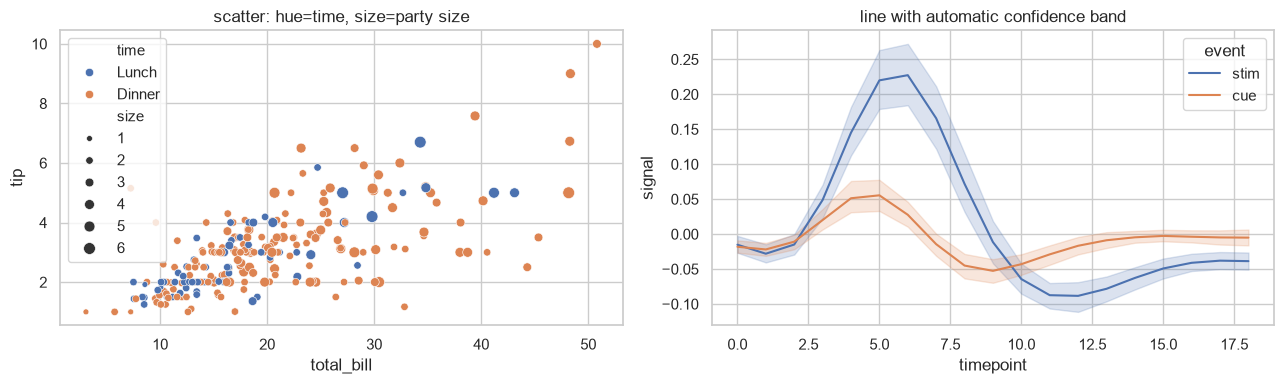

In [4]:
tips = sns.load_dataset("tips")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", size="size",
                ax=axes[0])
axes[0].set_title("scatter: hue=time, size=party size")

fmri = sns.load_dataset("fmri")
sns.lineplot(data=fmri, x="timepoint", y="signal", hue="event", ax=axes[1])
axes[1].set_title("line with automatic confidence band")
plt.tight_layout(); plt.show()

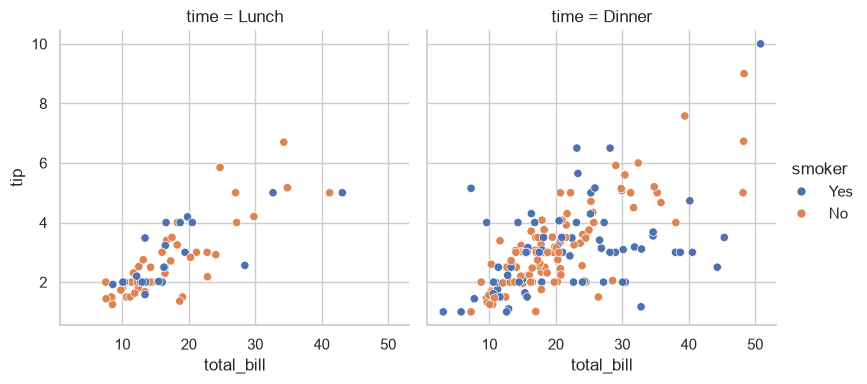

In [5]:
# relplot facets into a grid with col=
sns.relplot(data=tips, x="total_bill", y="tip", col="time", hue="smoker",
            height=4, aspect=1)
plt.show()

**Exercise 2** — Scatter `total_bill` vs `tip`, with point color by `day` and point style by `sex`.

In [6]:
# Your turn:

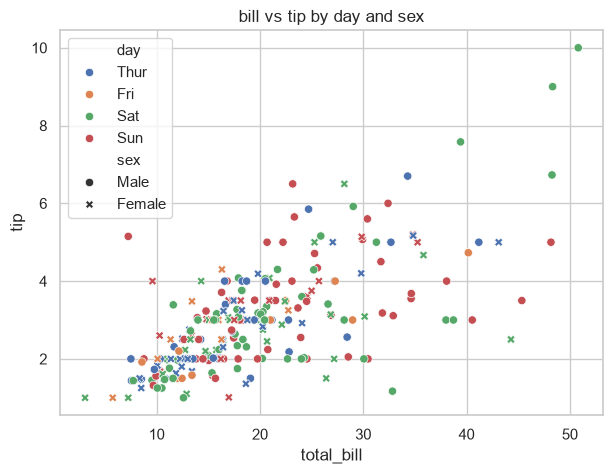

In [7]:
# Solution
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="day", style="sex", ax=ax)
ax.set_title("bill vs tip by day and sex")
plt.show()

## 3. Distribution Plots

Understand the shape of one or two variables: `histplot`, `kdeplot` (smooth density),
`ecdfplot` (cumulative), and figure-level `displot`.

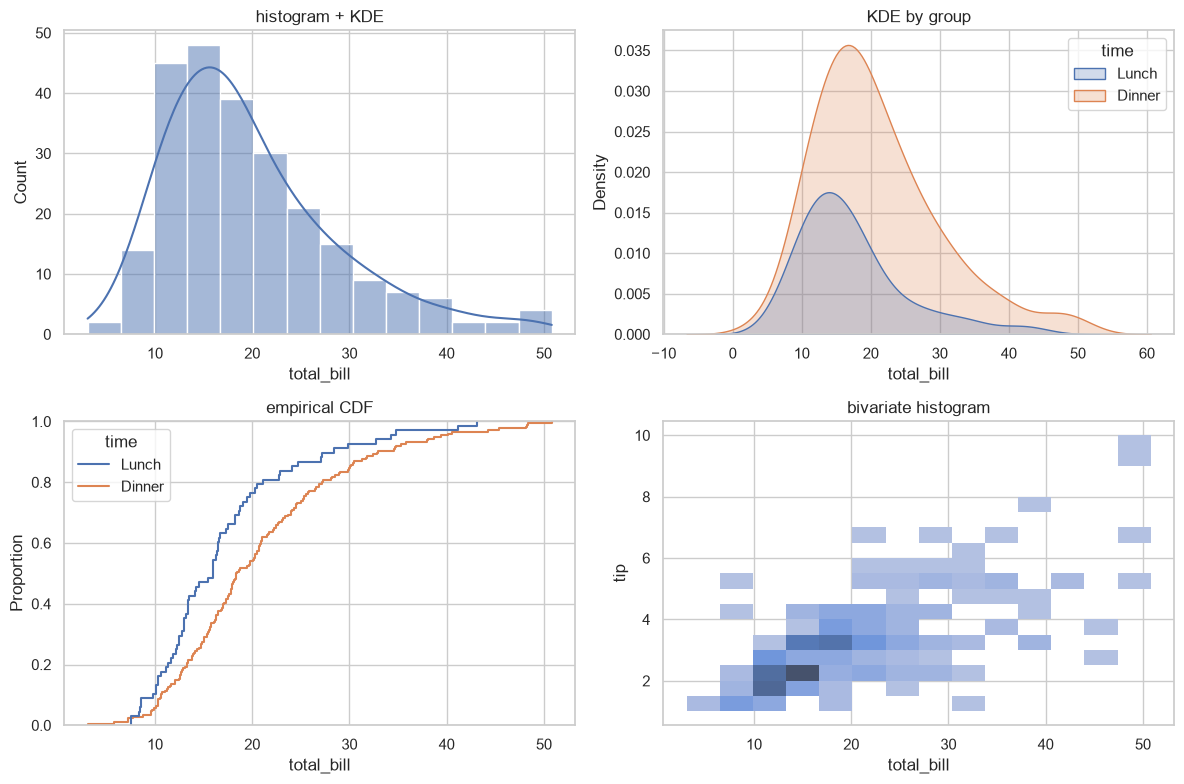

In [8]:
tips = sns.load_dataset("tips")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(data=tips, x="total_bill", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("histogram + KDE")

sns.kdeplot(data=tips, x="total_bill", hue="time", fill=True, ax=axes[0, 1])
axes[0, 1].set_title("KDE by group")

sns.ecdfplot(data=tips, x="total_bill", hue="time", ax=axes[1, 0])
axes[1, 0].set_title("empirical CDF")

sns.histplot(data=tips, x="total_bill", y="tip", ax=axes[1, 1])   # 2-D hist
axes[1, 1].set_title("bivariate histogram")
plt.tight_layout(); plt.show()

**Exercise 3** — Plot overlaid KDE curves of `total_bill` split by `sex`, filled with transparency.

In [9]:
# Your turn:

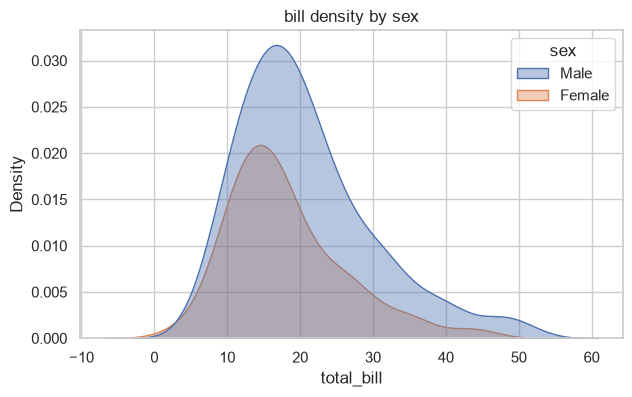

In [10]:
# Solution
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(data=tips, x="total_bill", hue="sex", fill=True, alpha=0.4, ax=ax)
ax.set_title("bill density by sex")
plt.show()

## 4. Categorical Plots

Compare a numeric variable across categories. Family: `boxplot`, `violinplot`, `stripplot`,
`swarmplot`, `barplot` (shows a mean + CI), `countplot` (frequencies), `pointplot`.
`catplot` is the figure-level wrapper (`kind=...`).

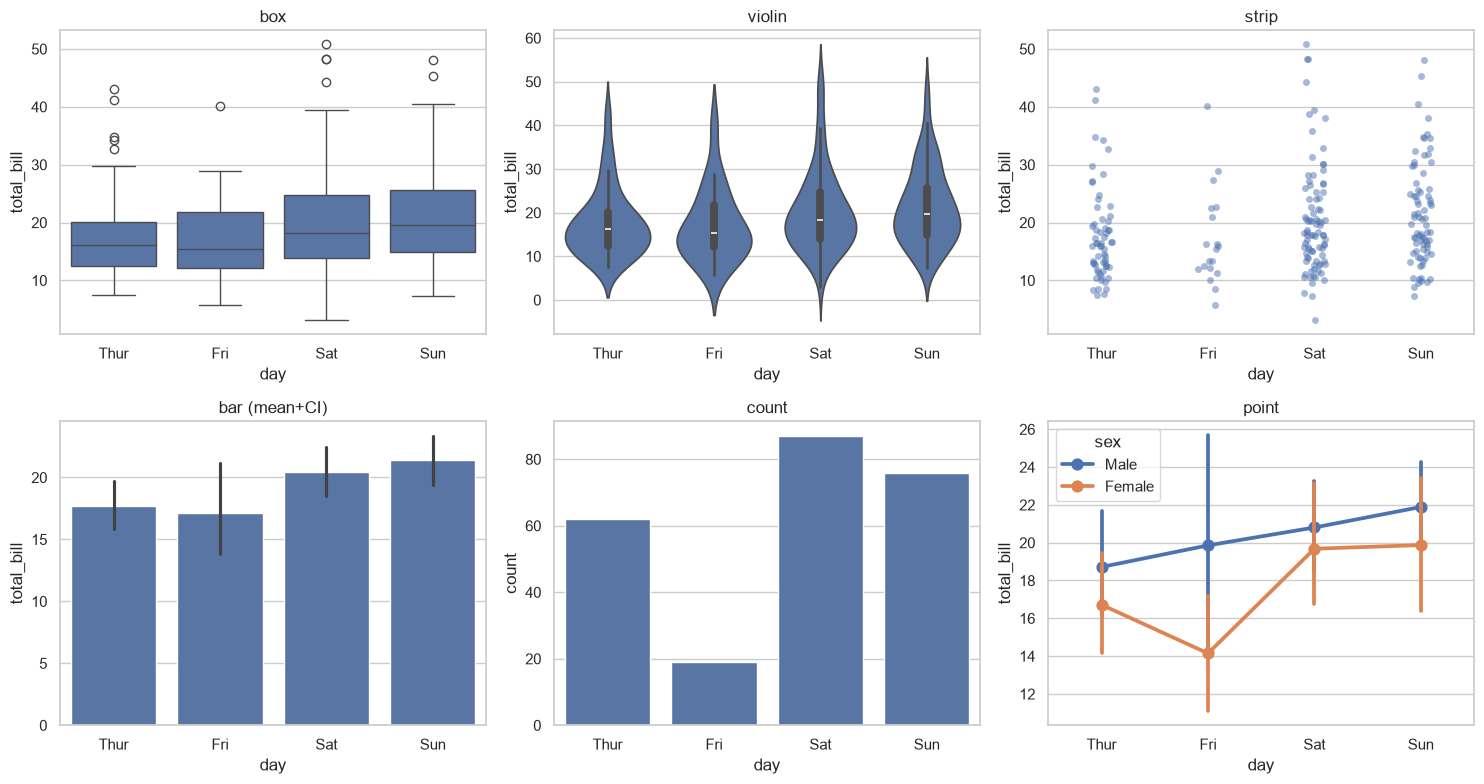

In [11]:
tips = sns.load_dataset("tips")
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.boxplot(data=tips, x="day", y="total_bill", ax=axes[0, 0]); axes[0, 0].set_title("box")
sns.violinplot(data=tips, x="day", y="total_bill", ax=axes[0, 1]); axes[0, 1].set_title("violin")
sns.stripplot(data=tips, x="day", y="total_bill", ax=axes[0, 2], alpha=0.5); axes[0, 2].set_title("strip")
sns.barplot(data=tips, x="day", y="total_bill", ax=axes[1, 0]); axes[1, 0].set_title("bar (mean+CI)")
sns.countplot(data=tips, x="day", ax=axes[1, 1]); axes[1, 1].set_title("count")
sns.pointplot(data=tips, x="day", y="total_bill", hue="sex", ax=axes[1, 2]); axes[1, 2].set_title("point")
plt.tight_layout(); plt.show()

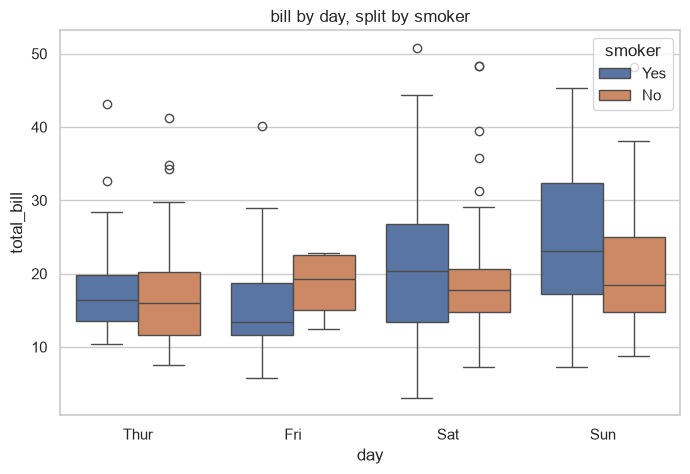

In [12]:
# A box split by a second category with hue, plus a swarm overlay
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=tips, x="day", y="total_bill", hue="smoker", ax=ax)
ax.set_title("bill by day, split by smoker")
plt.show()

**Exercise 4** — Make a violin plot of `total_bill` by `day`, split by `sex` (hue), using `split=True`.

In [13]:
# Your turn:

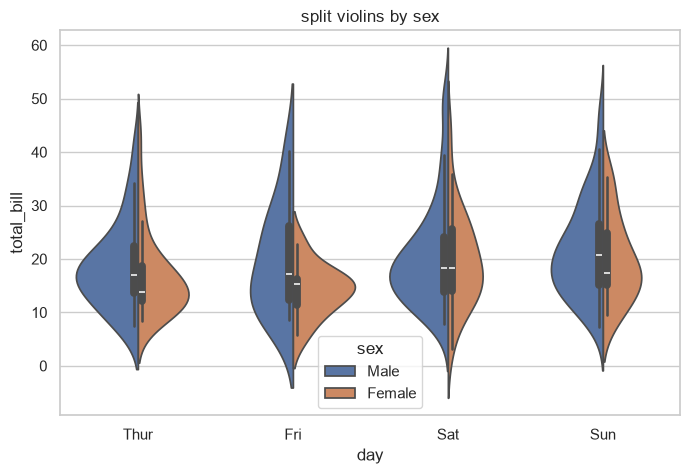

In [14]:
# Solution
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=tips, x="day", y="total_bill", hue="sex", split=True, ax=ax)
ax.set_title("split violins by sex")
plt.show()

## 5. Regression Plots

Visualize a linear trend with confidence band. `regplot` is axes-level; `lmplot` is
figure-level and can facet. `residplot` checks residuals.

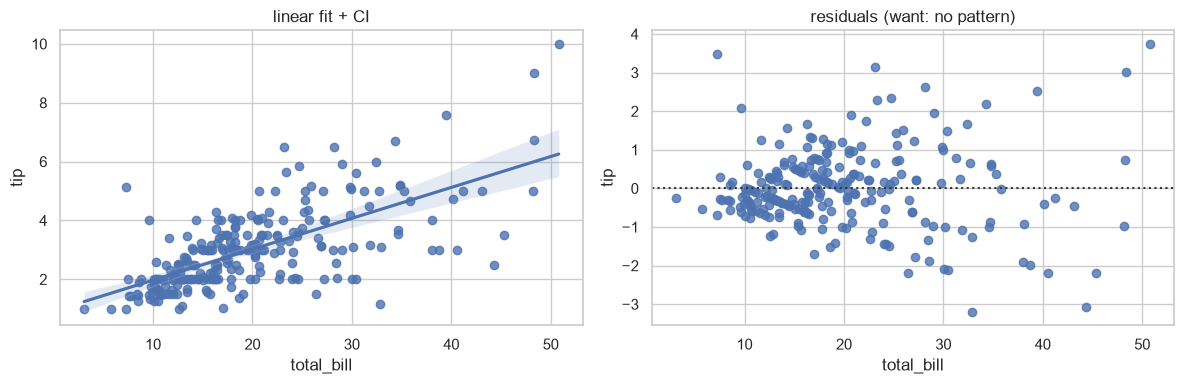

In [15]:
tips = sns.load_dataset("tips")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=tips, x="total_bill", y="tip", ax=axes[0])
axes[0].set_title("linear fit + CI")
sns.residplot(data=tips, x="total_bill", y="tip", ax=axes[1])
axes[1].set_title("residuals (want: no pattern)")
plt.tight_layout(); plt.show()

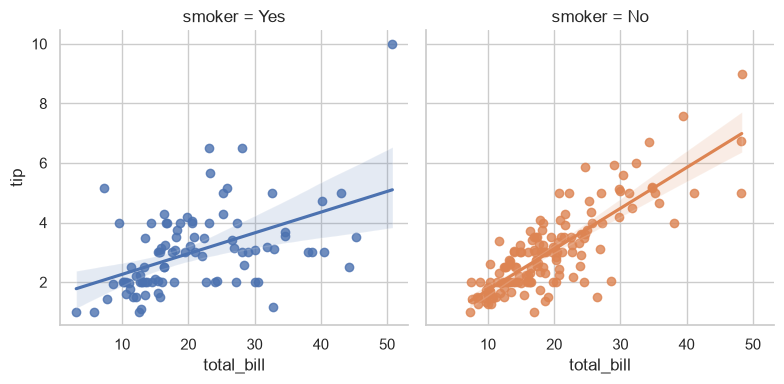

In [16]:
# lmplot facets regressions across a category
sns.lmplot(data=tips, x="total_bill", y="tip", col="smoker", hue="smoker", height=4)
plt.show()

**Exercise 5** — Use `lmplot` to fit `tip ~ total_bill` separately for each `time` (lunch/dinner) in side-by-side panels.

In [17]:
# Your turn:

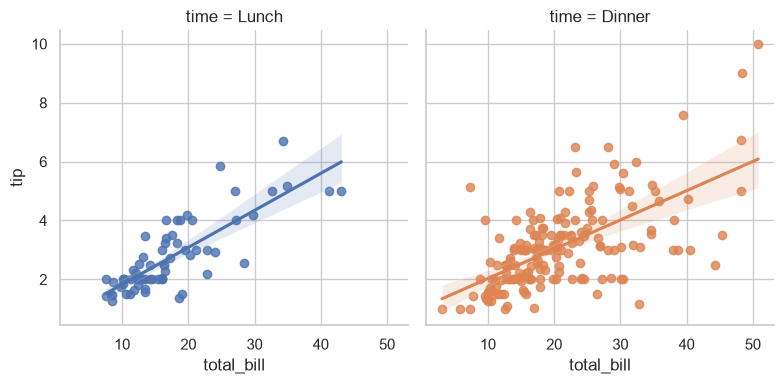

In [18]:
# Solution
sns.lmplot(data=tips, x="total_bill", y="tip", col="time", hue="time", height=4)
plt.show()

## 6. Matrix Plots

`heatmap` renders a matrix (great for correlations/confusion matrices).
`clustermap` reorders rows/cols by hierarchical clustering.

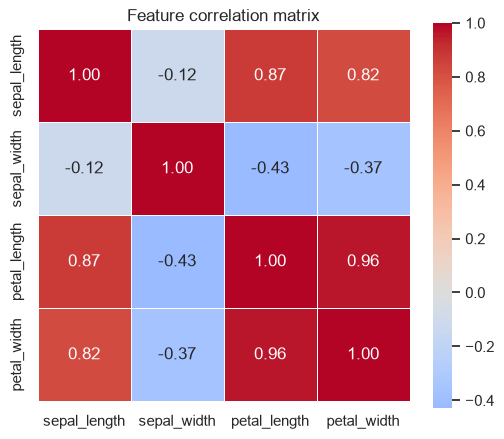

In [19]:
iris = sns.load_dataset("iris")
corr = iris.drop(columns="species").corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f",
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Feature correlation matrix")
plt.show()

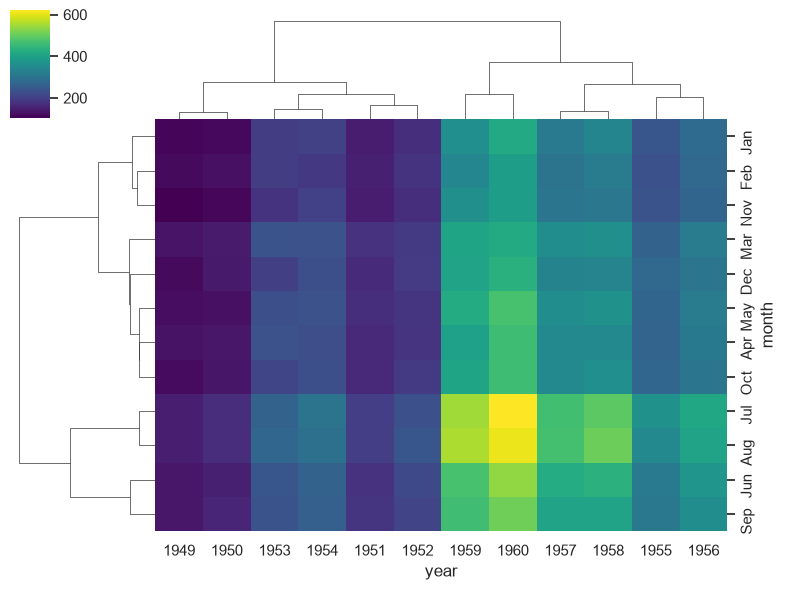

In [20]:
# Clustermap groups similar rows/columns together (manages its own figure)
flights = sns.load_dataset("flights").pivot(index="month", columns="year", values="passengers")
sns.clustermap(flights, cmap="viridis", figsize=(8, 6), z_score=None)
plt.show()

**Exercise 6** — Build a heatmap of the `flights` dataset as a month×year matrix of passenger counts, annotated.

In [21]:
# Your turn:

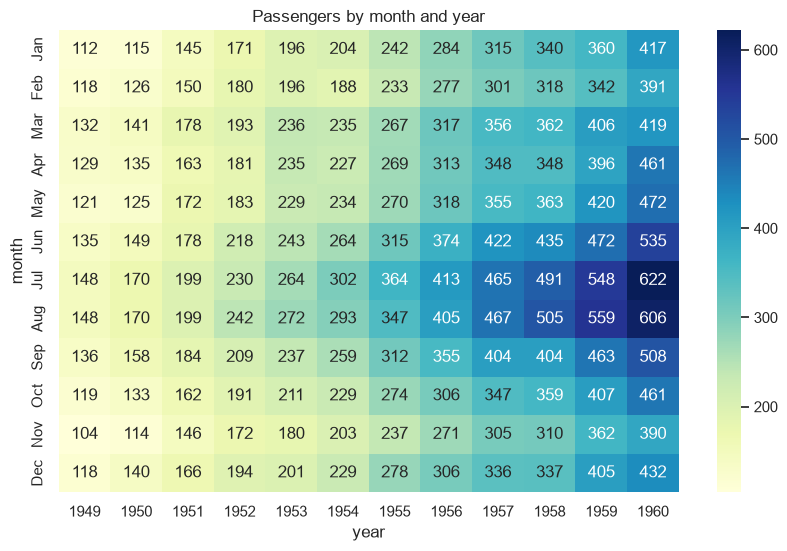

In [22]:
# Solution
flights = sns.load_dataset("flights").pivot(index="month", columns="year", values="passengers")
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(flights, cmap="YlGnBu", annot=True, fmt="d", ax=ax)
ax.set_title("Passengers by month and year")
plt.show()

## 7. Multi-Plot Grids

- `pairplot` — every pairwise scatter + diagonal distributions.
- `jointplot` — one bivariate plot plus marginal distributions.
- `FacetGrid` — map any plot across a grid defined by categorical columns.

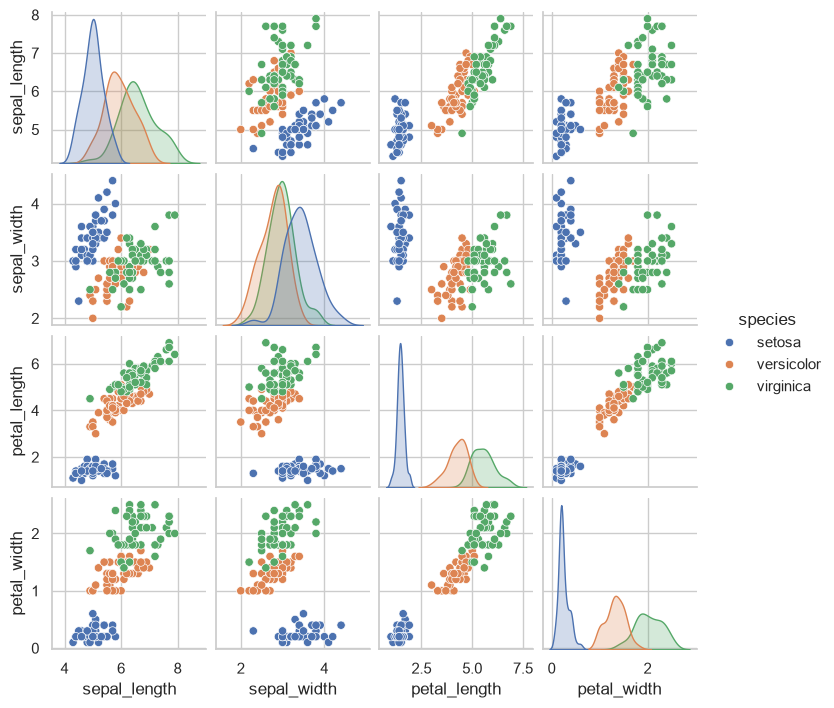

In [23]:
iris = sns.load_dataset("iris")
sns.pairplot(iris, hue="species", diag_kind="kde", height=1.8)
plt.show()

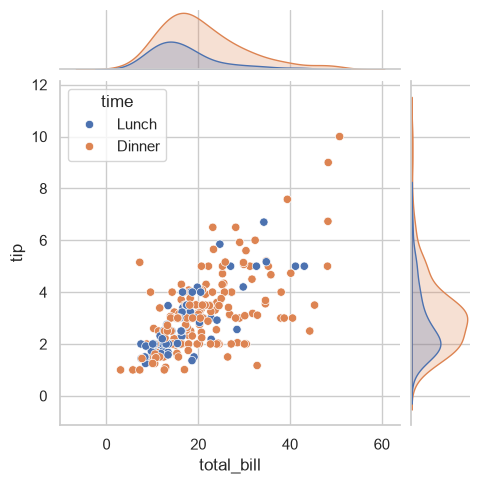

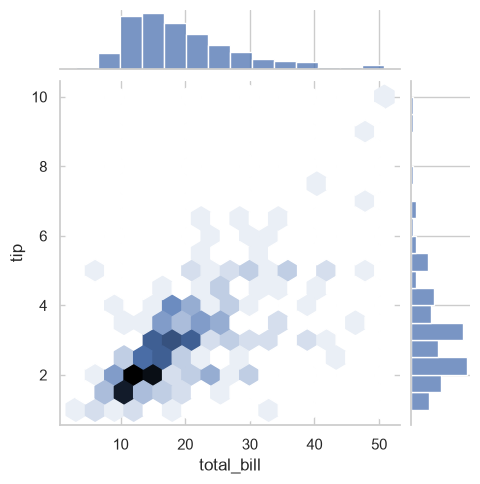

In [24]:
tips = sns.load_dataset("tips")
sns.jointplot(data=tips, x="total_bill", y="tip", hue="time", kind="scatter", height=5)
plt.show()
sns.jointplot(data=tips, x="total_bill", y="tip", kind="hex", height=5)
plt.show()

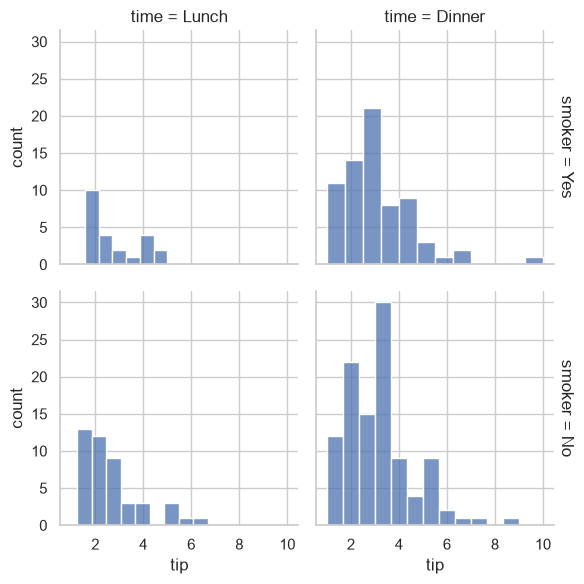

In [25]:
# FacetGrid: histogram of tips across a 2-D grid of categories
g = sns.FacetGrid(tips, col="time", row="smoker", height=3, margin_titles=True)
g.map_dataframe(sns.histplot, x="tip")
g.set_axis_labels("tip", "count")
plt.show()

**Exercise 7** — Make a `pairplot` of the `penguins` dataset colored by `species` (drop NA rows first).

In [26]:
# Your turn:

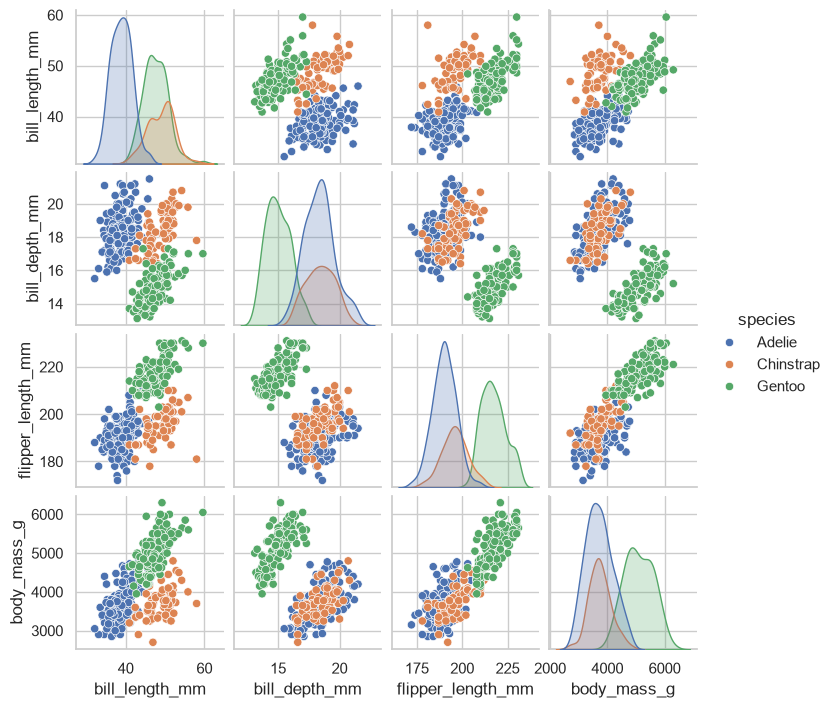

In [27]:
# Solution
penguins = sns.load_dataset("penguins").dropna()
sns.pairplot(penguins, hue="species", height=1.8)
plt.show()

## 8. Color Palettes & Styling

seaborn gives you qualitative, sequential, and diverging palettes plus theme controls.
Match the palette type to the data: categories → qualitative, ordered magnitude →
sequential, deviation around a center → diverging.

deep


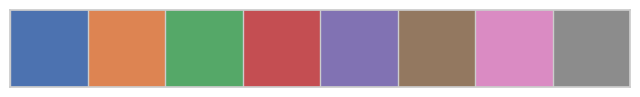

Set2


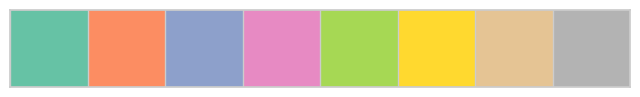

viridis


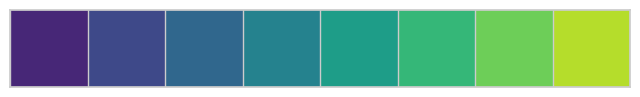

rocket


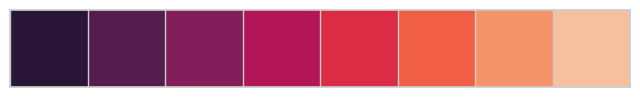

coolwarm


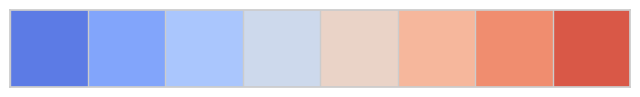

In [28]:
# Visualize a few palettes
for name in ["deep", "Set2", "viridis", "rocket", "coolwarm"]:
    print(name)
    sns.palplot(sns.color_palette(name, 8))
    plt.show()

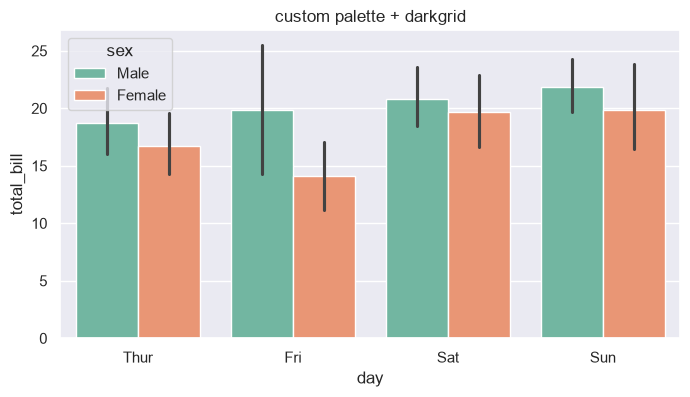

In [29]:
tips = sns.load_dataset("tips")
# Apply a palette and a theme context together
with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=tips, x="day", y="total_bill", hue="sex",
                palette="Set2", ax=ax)
    ax.set_title("custom palette + darkgrid")
    plt.show()

sns.set_theme()   # reset to defaults

**Exercise 8** — Draw a boxplot of `total_bill` by `day` using the `'rocket'` palette, with the `'ticks'` style.

In [30]:
# Your turn:

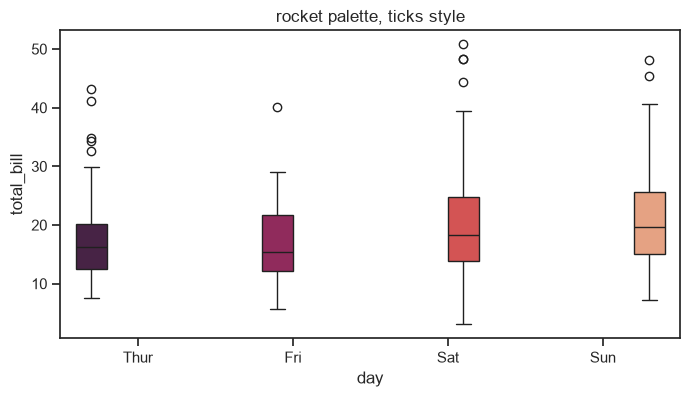

In [31]:
# Solution
with sns.axes_style("ticks"):
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=tips, x="day", y="total_bill", hue="day",
                palette="rocket", legend=False, ax=ax)
    ax.set_title("rocket palette, ticks style")
    plt.show()
sns.set_theme()

## 9. 🏆 Capstone

Combine datasets, faceting, and styling into analyses. Try before peeking.

**Capstone A — Tips deep-dive.** Using `tips`: (1) a figure-level `catplot` of tip percentage (`tip/total_bill`) by day, split by sex; (2) a correlation heatmap of the numeric columns; (3) a `jointplot` of bill vs tip with a regression line (`kind='reg'`).

In [32]:
# Your turn:

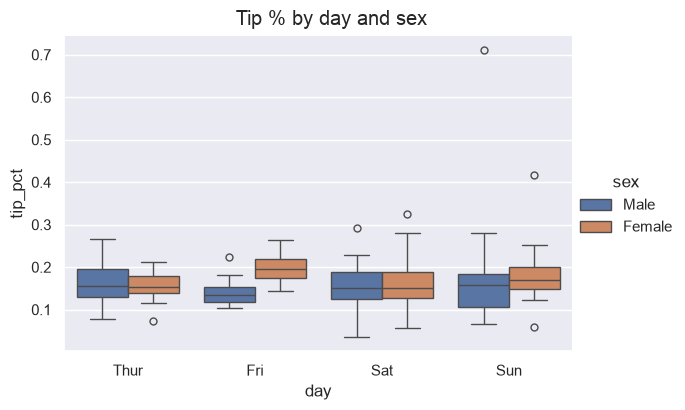

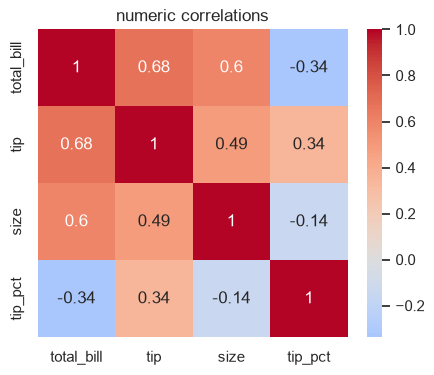

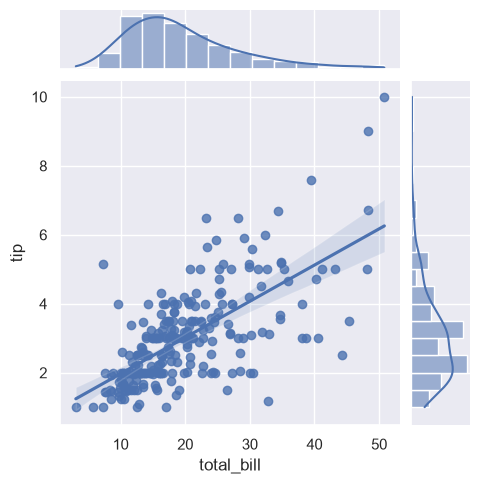

In [33]:
# Solution
tips = sns.load_dataset("tips").copy()
tips["tip_pct"] = tips["tip"] / tips["total_bill"]

# (1)
sns.catplot(data=tips, x="day", y="tip_pct", hue="sex", kind="box", height=4, aspect=1.5)
plt.suptitle("Tip % by day and sex", y=1.02)
plt.show()

# (2)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(tips[["total_bill", "tip", "size", "tip_pct"]].corr(),
            annot=True, cmap="coolwarm", center=0, ax=ax)
ax.set_title("numeric correlations")
plt.show()

# (3)
sns.jointplot(data=tips, x="total_bill", y="tip", kind="reg", height=5)
plt.show()

**Capstone B — Penguins classification view.** Using `penguins` (drop NA): (1) a `pairplot` colored by species; (2) a violin plot of body mass by species and sex; (3) a scatter of bill length vs depth with species as hue and island as style.

In [34]:
# Your turn:

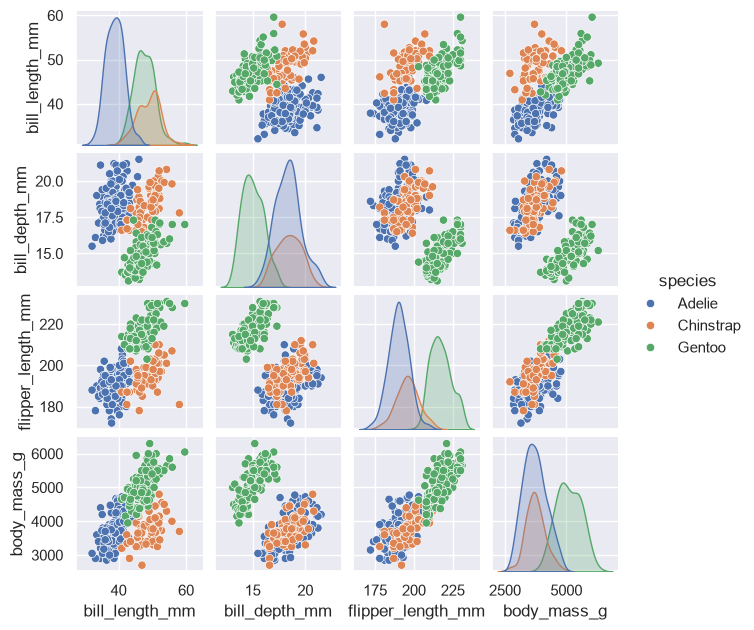

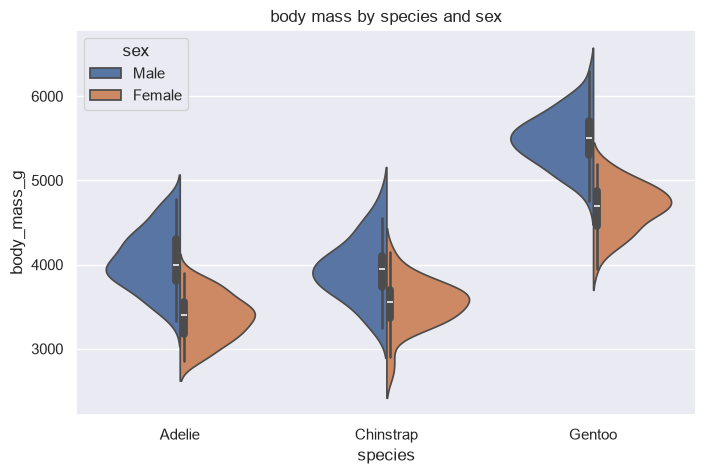

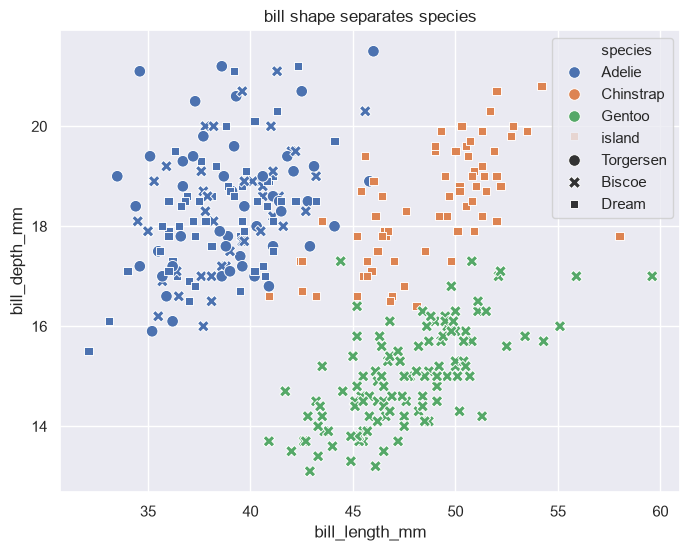

In [35]:
# Solution
pen = sns.load_dataset("penguins").dropna()

sns.pairplot(pen, hue="species", height=1.6)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=pen, x="species", y="body_mass_g", hue="sex", split=True, ax=ax)
ax.set_title("body mass by species and sex")
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=pen, x="bill_length_mm", y="bill_depth_mm",
                hue="species", style="island", s=70, ax=ax)
ax.set_title("bill shape separates species")
plt.show()

---
## 🎓 Next Steps
- Keep data **tidy** — it's the key to seaborn's one-line power.
- Reach for figure-level functions (`relplot`/`displot`/`catplot`) when you need facets.
- Drop into matplotlib (`ax=`) whenever you need fine control over a seaborn chart.